# 02 - Models, comparison and explainability (SHAP + LIME)

Models are trained by `python src/train.py` (about 20 minutes, mostly tuning). This notebook loads the results and the saved model, shows the comparison from **weak to strong**, explains the selected model with **SHAP** and **LIME**, and runs inference on one held-out customer.

**Pipeline used for every model** (`src/train.py`): feature engineering (`src/features.py`) -> median imputation -> (Logistic Regression only: signed log transform + standard scaling) -> model. Class imbalance is handled with class weights (`class_weight="balanced"`, `scale_pos_weight`, `auto_class_weights`).

In [1]:
import sys, json, pickle, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")
import config
from features import RAW_FEATURES, USAGE_TYPES, readable
from IPython.display import Image, display
res = pd.read_csv("../reports/model_comparison.csv")
info = json.loads(open("../models/feature_info.json").read())
print("Selected model:", info["model_name"])
res.round(4)

Selected model: XGBoost


,model,val_pr_auc,val_f1,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,test_pr_auc,train_f1,train_time_s
0,Majority baseline,0.2311,0.0000,0.7710,0.0000,0.0000,0.0000,0.5000,0.2290,0.0000,0.6217
1,Logistic Regression,0.9332,0.8399,0.9167,0.7628,0.9234,0.8354,0.9749,0.9291,0.8426,2.2693
2,Decision Tree,0.7683,0.7053,0.8603,0.6613,0.7995,0.7238,0.9118,0.7801,0.7348,3.5819
3,Random Forest,0.9370,0.8550,0.9328,0.8429,0.8687,0.8556,0.9771,0.9381,0.9787,32.7901
4,AdaBoost,0.9857,0.9374,0.9732,0.9494,0.9325,0.9409,0.9954,0.9864,0.9511,306.9556
5,XGBoost,0.9925,0.9568,0.9800,0.9435,0.9708,0.9570,0.9976,0.9927,0.9894,5.2649
6,LightGBM,0.9931,0.9615,0.9825,0.9541,0.9704,0.9622,0.9979,0.9937,0.9954,5.8627
7,CatBoost,0.9930,0.9590,0.9813,0.9404,0.9805,0.9600,0.9980,0.9941,0.9737,12.3902
8,Soft Voting (XGB + LGBM + CatBoost),0.9935,0.9603,0.9820,0.9489,0.9738,0.9612,0.9980,0.9940,0.9896,23.1610
9,Stacking (RF + XGB + LGBM -> LR),0.9904,0.9623,0.9830,0.9587,0.9674,0.9630,0.9973,0.9909,0.9954,215.4830


## 1. Why these models, from weak to strong

| Model | Family | Idea |
|---|---|---|
| Majority baseline | none | Always says "stays". Shows what accuracy means without learning |
| Logistic Regression | weak / linear | One weighted sum of the features. Fast and readable, but only straight-line boundaries |
| Decision Tree | single tree | If-then rules. Easy to read, but unstable (high variance) |
| Random Forest | **bagging** | Hundreds of trees on random samples and features, votes averaged: lowers variance |
| AdaBoost | **boosting** | Small trees one after another; each focuses on the customers the previous ones got wrong |
| XGBoost, LightGBM, CatBoost | **gradient boosting** | Each new tree fits the remaining error, with regularisation; the strongest models for tabular data |
| Soft Voting | **ensemble** | Averages the probabilities of XGBoost, LightGBM and CatBoost (fixed rule) |
| Stacking | **ensemble** | A Logistic Regression meta-model *learns* how to combine Random Forest, XGBoost and LightGBM |

## 2. Hyperparameters: designed values vs tuned values

In [2]:
pd.read_csv("../reports/hyperparameters.csv")

,model,parameter,designed,tuned,changed
0,XGBoost,n_estimators,400,300,True
1,XGBoost,max_depth,5,5,False
2,XGBoost,learning_rate,0.05,0.1,True
3,XGBoost,subsample,0.8,0.7,True
4,XGBoost,colsample_bytree,0.8,1.0,True
5,XGBoost,min_child_weight,5,10,True
6,XGBoost,gamma,0.1,0,True
7,XGBoost,reg_lambda,1.5,3.0,True
8,LightGBM,n_estimators,400,500,True
9,LightGBM,num_leaves,31,15,True


Every model has hand-set (non-default) parameters in `src/train.py`, each with a comment. Random Forest, XGBoost and LightGBM were then refined with `RandomizedSearchCV` (stratified 3-fold cross-validation, scored by PR-AUC, which focuses on the churn class). The test set was **not** used for tuning or for choosing the model: the final model was chosen on a separate validation part of the training data.

## 3. Results on the test set (13,000 customers never seen in training)

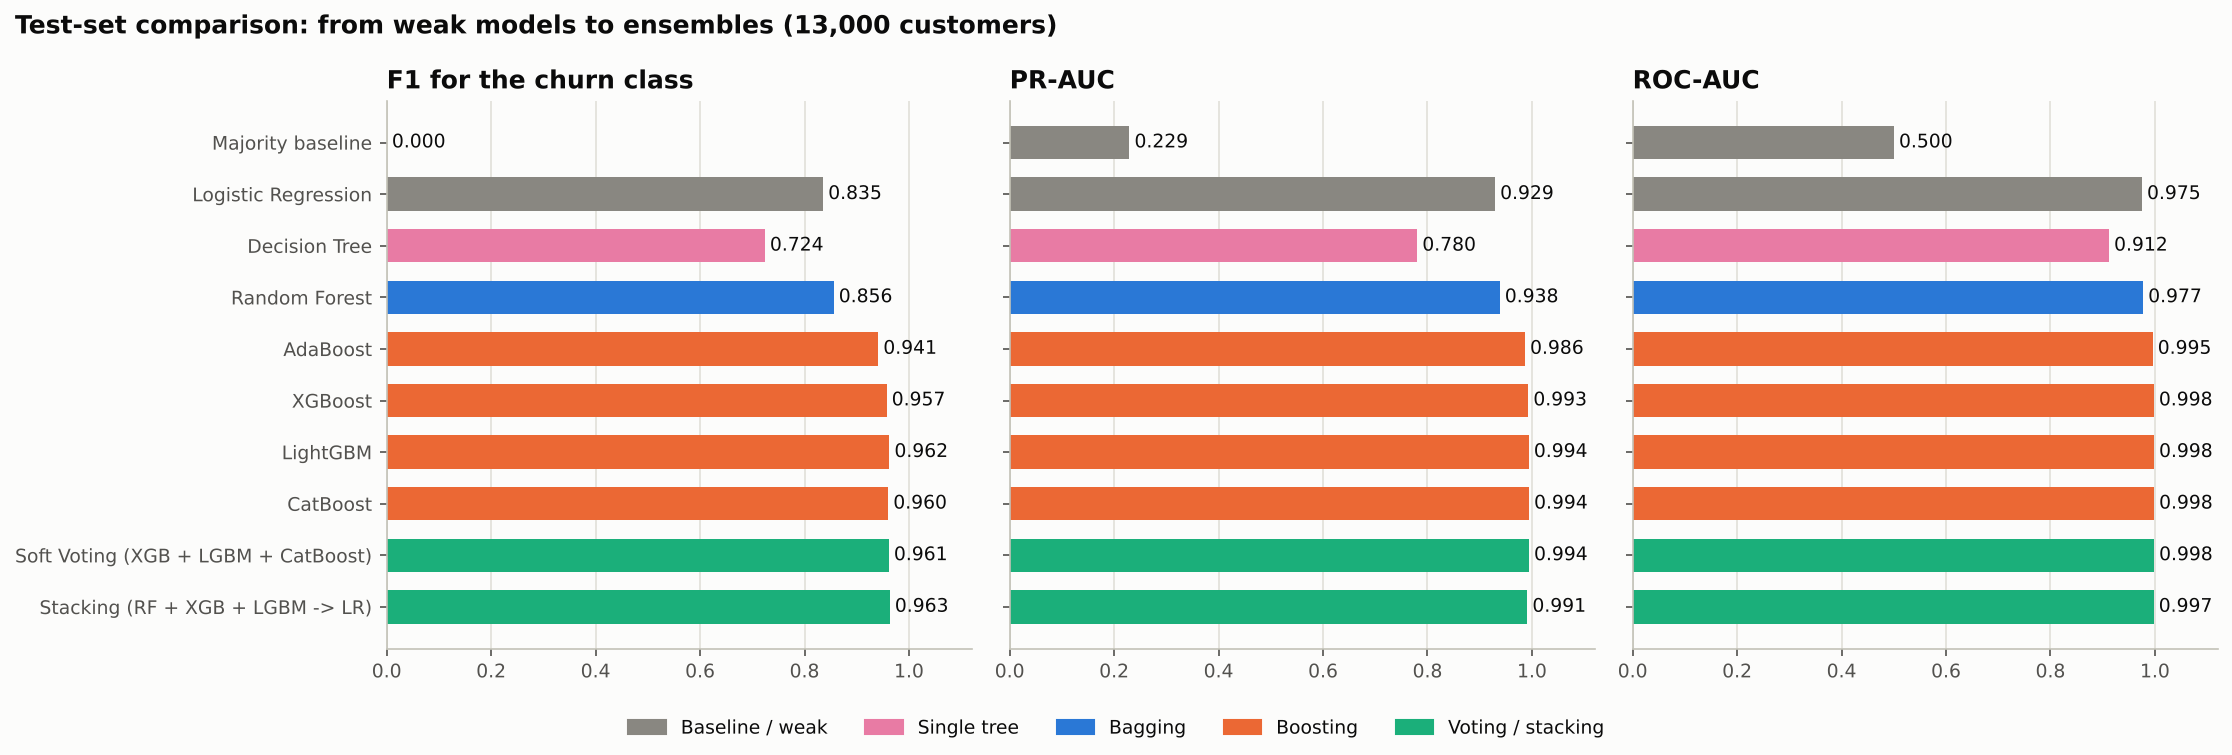

In [3]:
display(Image("../reports/figures/model_comparison.png"))

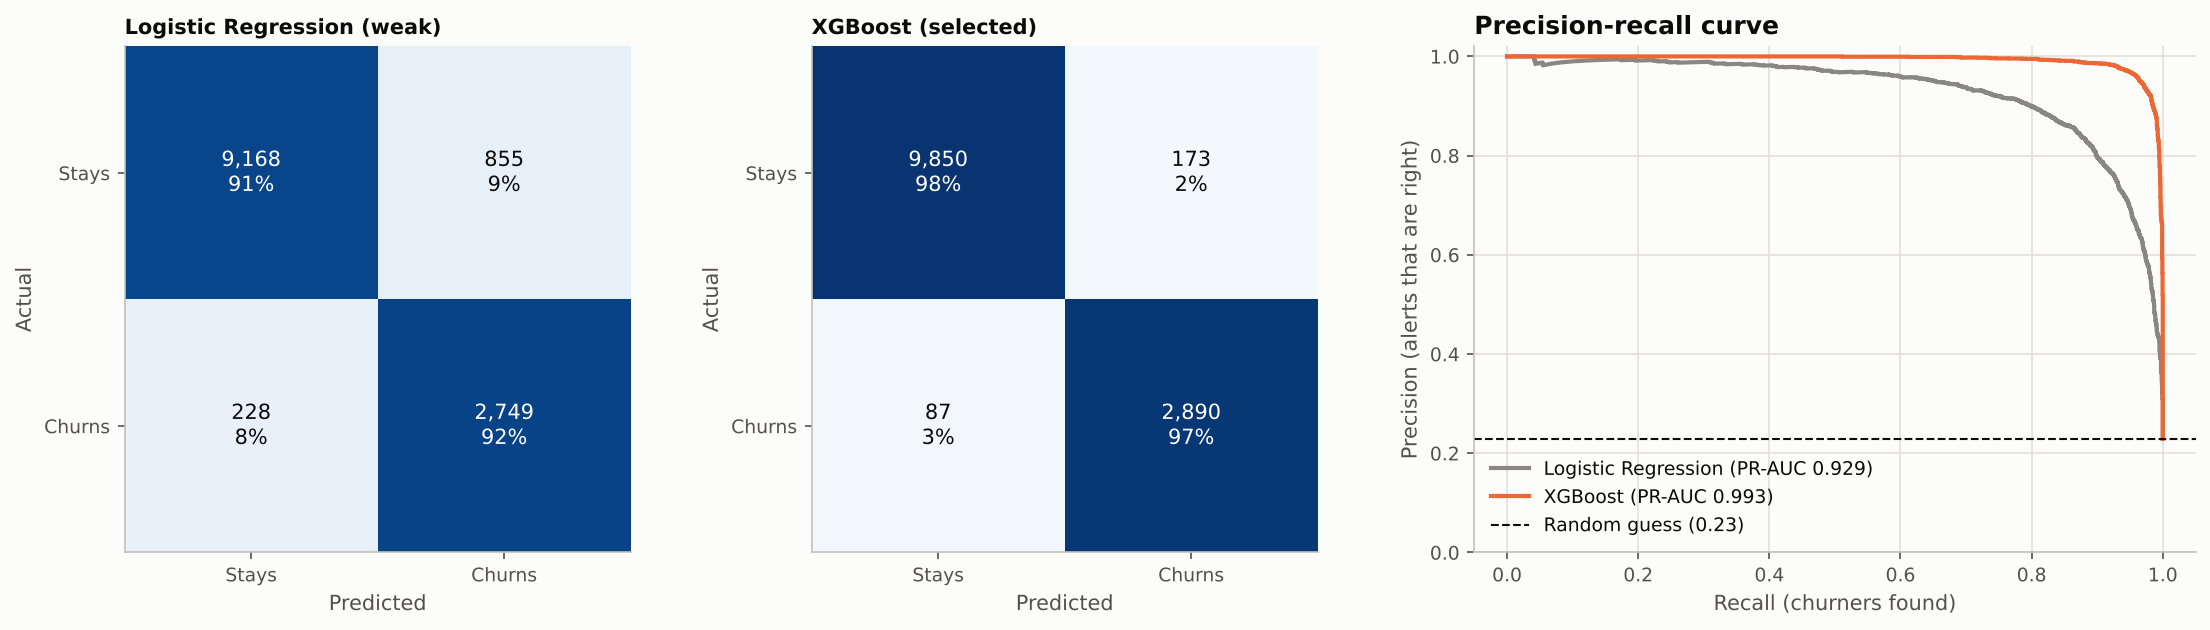

In [4]:
display(Image("../reports/figures/weak_vs_best.png"))

## 4. Explainability: SHAP (global)

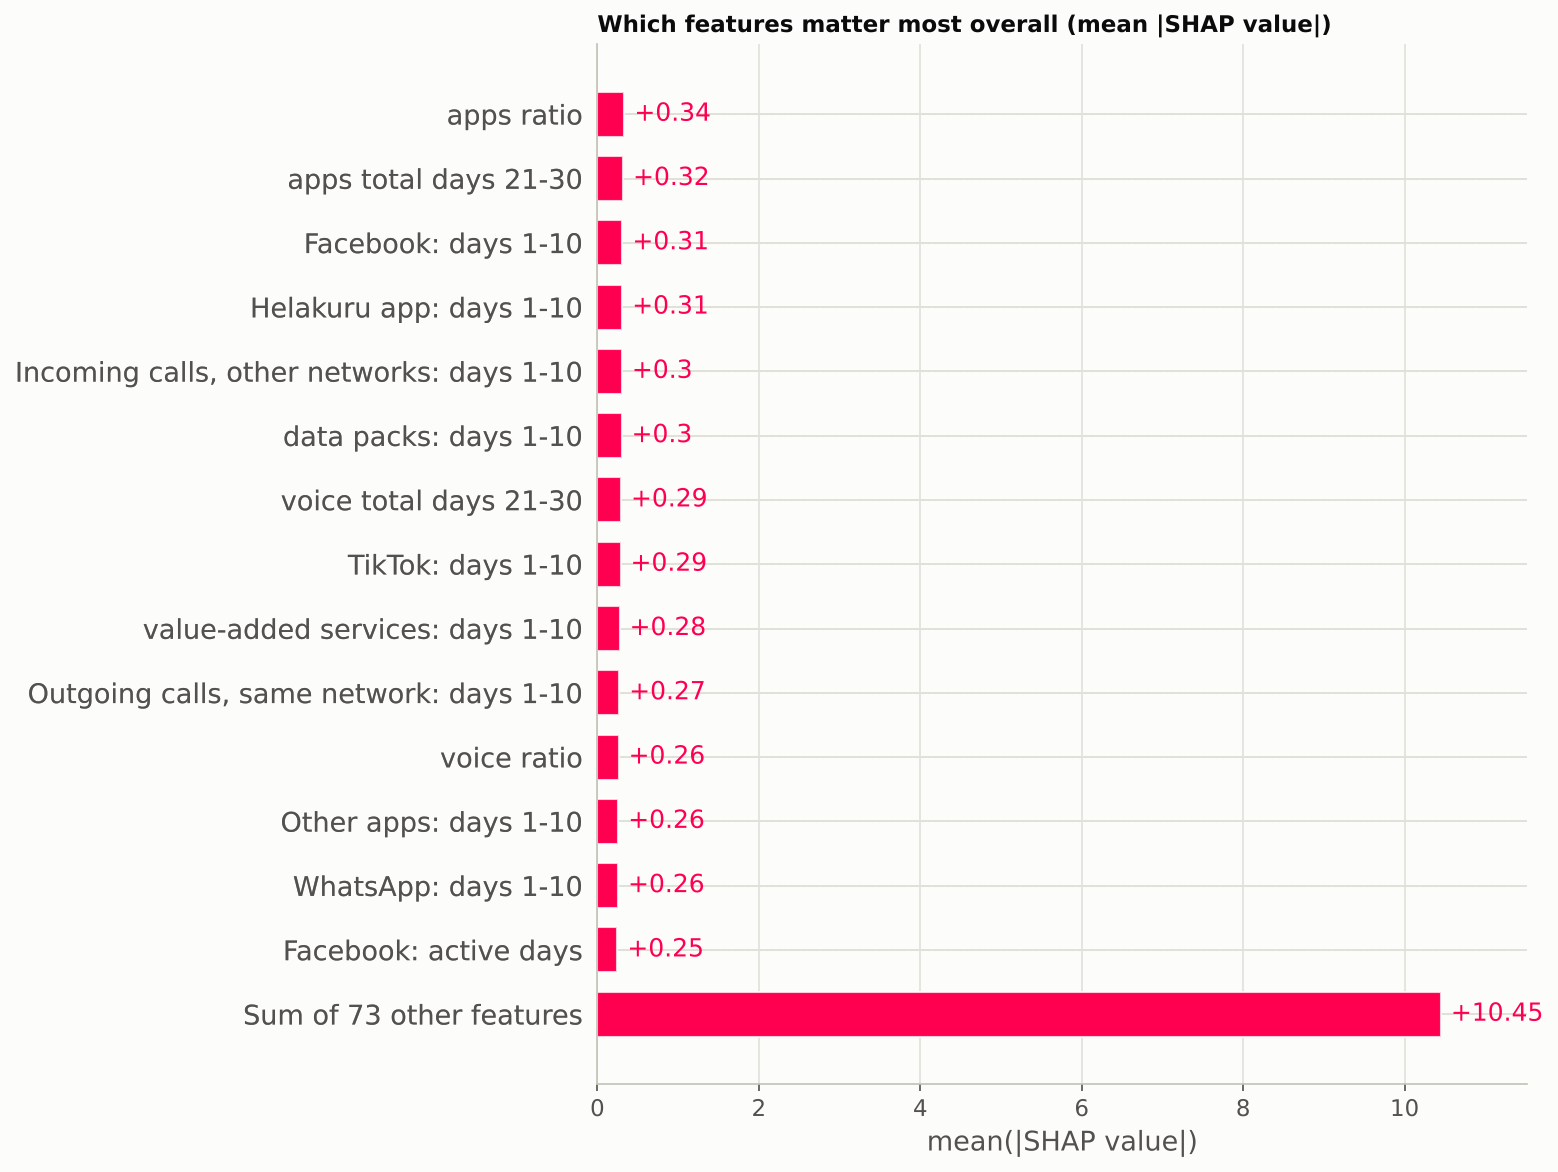

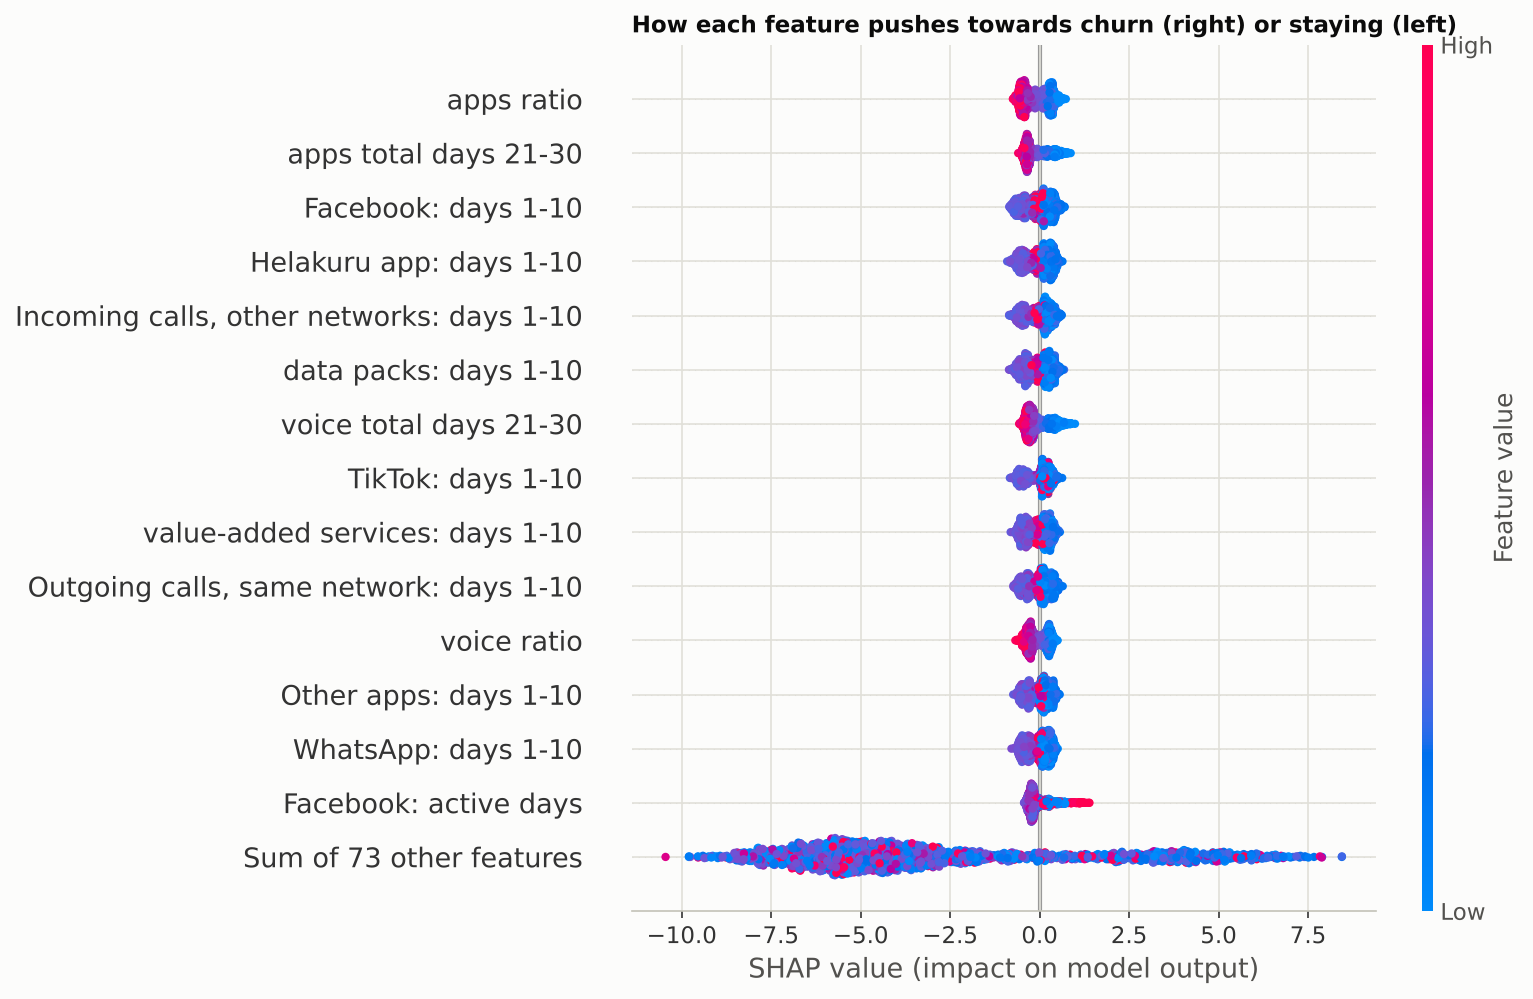

In [5]:
display(Image("../reports/figures/shap_importance.png"))
display(Image("../reports/figures/shap_beeswarm.png"))

**How to read the beeswarm:** each dot is one customer. Red = a high value of that feature, blue = a low value. Dots on the right push the prediction towards **churn**, dots on the left towards **staying**.

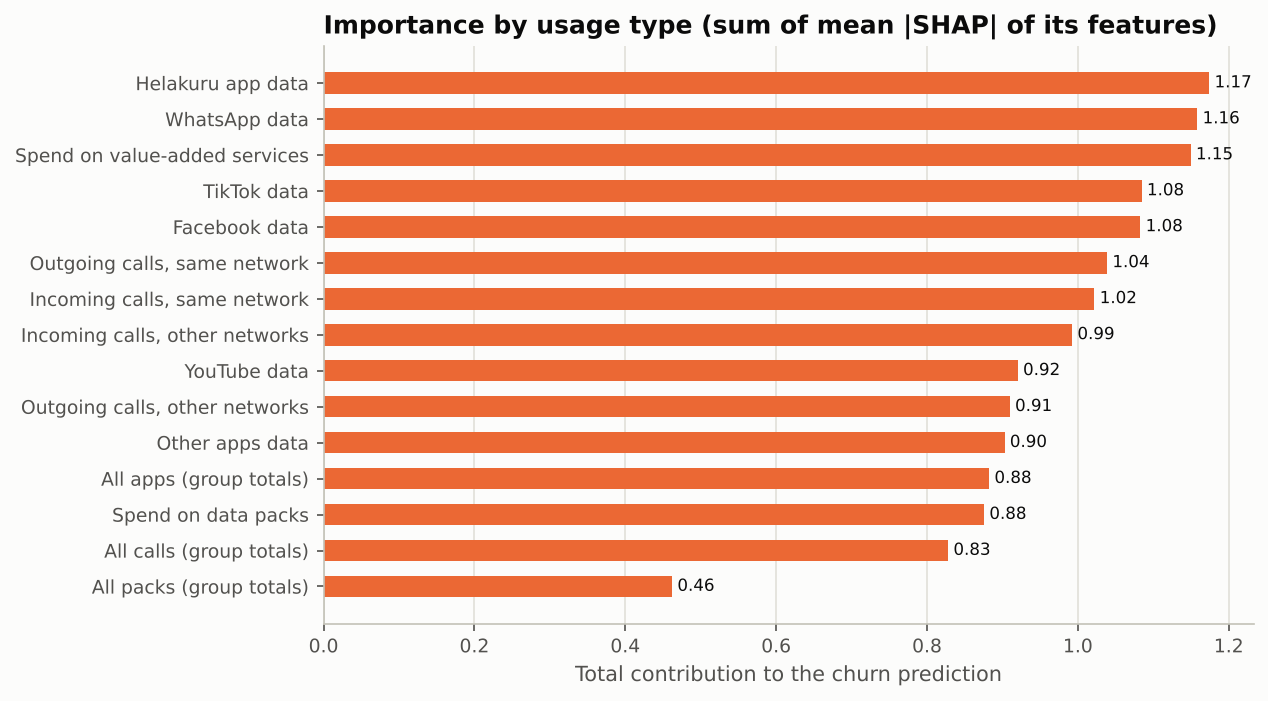

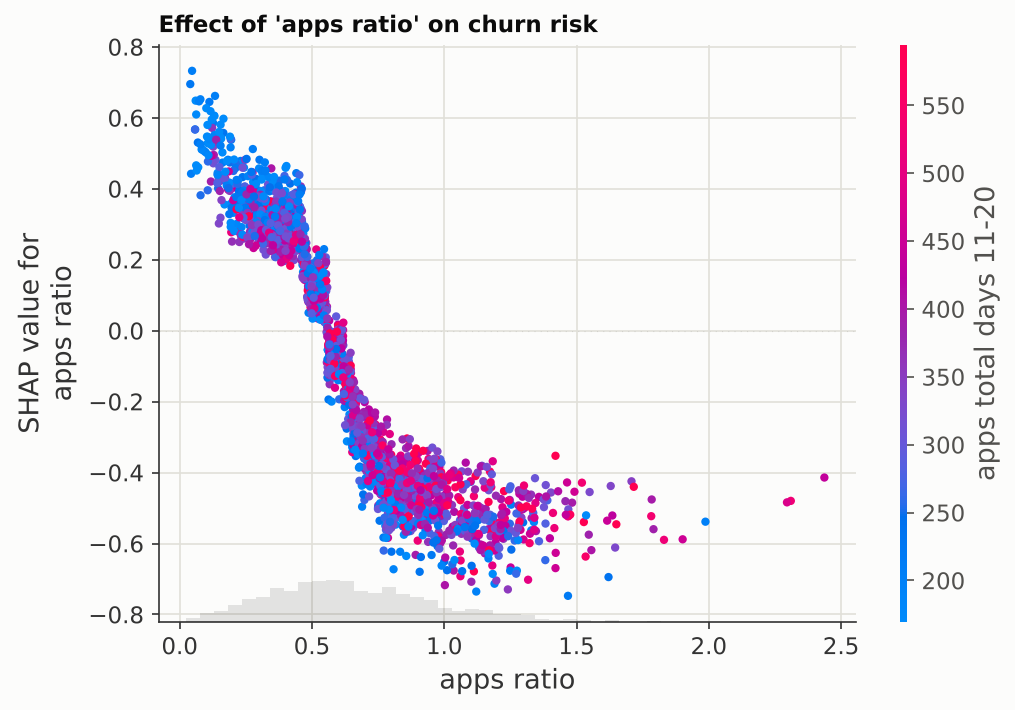

In [6]:
display(Image("../reports/figures/shap_by_usage_type.png"))
display(Image("../reports/figures/shap_dependence_top.png"))

**What SHAP tells us**
- No single app or service decides churn. The importance is spread across all 12 usage types: churn shows up as a **decline in everything at once** (apps, packs and calls).
- Small daily-habit services rank highest: **Helakuru, WhatsApp and value-added services**. When a customer stops these, they are close to leaving.
- The engineered features matter: the **apps end/start ratio** and the **apps and calls totals in days 21-30** are the top single features. A falling ratio and low end-of-month usage push towards churn.

## 5. One customer: inference, SHAP waterfall and LIME

In [7]:
model = pickle.load(open("../models/model.pkl", "rb"))          # pickle loader
sample = pd.read_csv("../data/processed/inference_sample.csv")
prob = model.predict_proba(sample[RAW_FEATURES])[0, 1]
print(f"Held-out customer -> churn probability {prob:.3f} -> predicted "
      f"{config.CLASS_LABELS[int(prob >= 0.5)]} | actual {config.CLASS_LABELS[int(sample.churn.iloc[0])]}")
pd.DataFrame({"days 1-10": [sample[f"{u}_d01_10"].iloc[0] for u in USAGE_TYPES],
              "days 21-30": [sample[f"{u}_d21_30"].iloc[0] for u in USAGE_TYPES]},
             index=list(USAGE_TYPES.values())).round(1)

Held-out customer -> churn probability 0.998 -> predicted Churns | actual Churns


,days 1-10,days 21-30
Facebook data (MB per day),32.1,10.1
TikTok data (MB per day),62.9,15.8
YouTube data (MB per day),210.8,149.8
WhatsApp data (MB per day),9.4,7.1
Helakuru app data (MB per day),8.2,0.5
Other apps data (MB per day),225.2,111.8
Spend on data packs (LKR per day),167.9,153.2
Spend on value-added services (LKR per day),17.8,0.0
"Outgoing calls, same network (min per day)",17.3,0.0
"Outgoing calls, other networks (min per day)",43.7,31.6


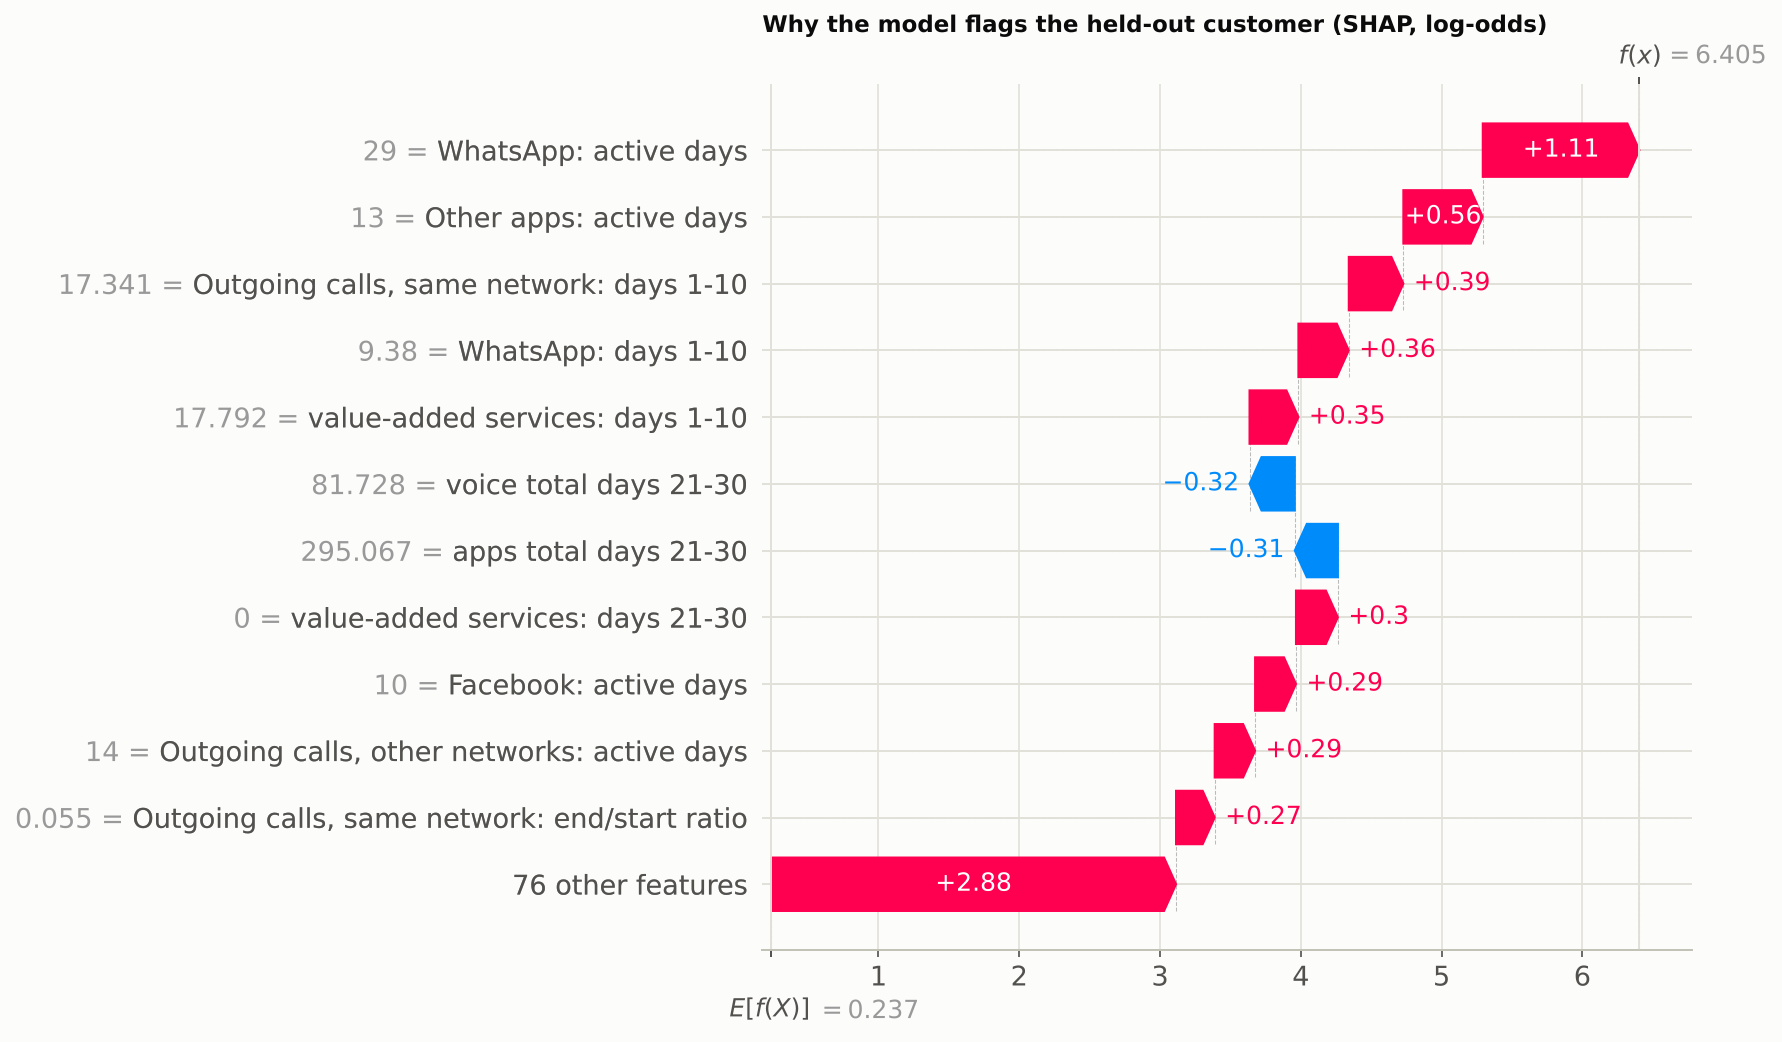

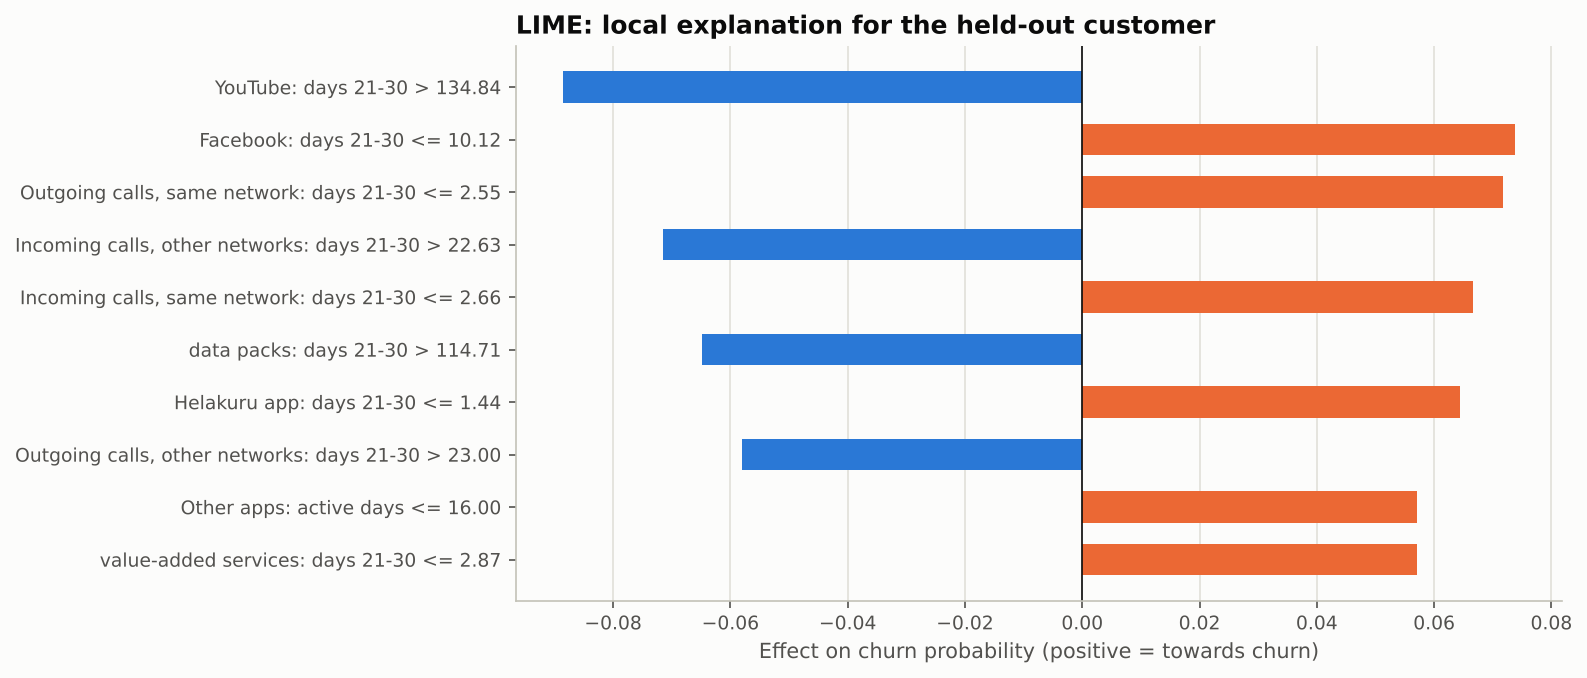

{'model': 'XGBoost',
 'explained_member': None,
 'holdout_churn_probability': 0.9983,
 'holdout_true_label': 1,
 'shap_top10': {'apps ratio': 0.3353999853134155,
  'apps total days 21-30': 0.3188999891281128,
  'Facebook: days 1-10': 0.3109999895095825,
  'Helakuru app: days 1-10': 0.3084000051021576,
  'Incoming calls, other networks: days 1-10': 0.304500013589859,
  'data packs: days 1-10': 0.3005000054836273,
  'voice total days 21-30': 0.2930999994277954,
  'TikTok: days 1-10': 0.28769999742507935,
  'value-added services: days 1-10': 0.2757999897003174,
  'Outgoing calls, same network: days 1-10': 0.27079999446868896},
 'shap_by_usage_type': {'Helakuru app data': 1.1740000247955322,
  'WhatsApp data': 1.1579999923706055,
  'Spend on value-added services': 1.149999976158142,
  'TikTok data': 1.0850000381469727,
  'Facebook data': 1.0829999446868896,
  'Outgoing calls, same network': 1.0390000343322754,
  'Incoming calls, same network': 1.0219999551773071,
  'Incoming calls, other n

In [8]:
display(Image("../reports/figures/shap_waterfall_holdout.png"))
display(Image("../reports/figures/lime_holdout.png"))
json.loads(open("../reports/explainability_summary.json").read())

**SHAP vs LIME**

| | SHAP | LIME |
|---|---|---|
| Idea | Fair share of each feature in the prediction (Shapley values from game theory) | Fits a small linear model around one customer by testing slightly changed copies |
| Scope | Global ranking **and** per customer | Per customer only |
| Strength | Consistent, exact for tree models, adds up to the prediction | Works with any model (here the full pipeline) |
| Weakness | Slower for non-tree models | Results change a little with the random samples; uses ranges of values |

When both methods point to the same features for the same customer, we can trust the explanation more.